# Linear Algebra II: Inner Products, Projections, Determinants, and Diagonalization

`f1_linear_algebra.ipynb` introduced vectors, matrices, least squares, eigenvalues, and the SVD.
This companion notebook fills the remaining CSC604 Module 2 topics:

- inner products, length, distance, angles, and orthogonal vectors;
- orthogonal projections and the geometry of least squares;
- determinants and traces;
- symmetric positive definite matrices and quadratic forms;
- diagonalization and the eigendecomposition of symmetric matrices.

The goal is to make each definition computable and to connect it to a machine-learning operation
you have already seen.

## Learning objectives

By the end of this notebook you can:

- compute an inner product, norm, distance, angle, and orthogonality check with NumPy;
- project a vector onto a line or a column space and verify that the residual is orthogonal;
- explain what a determinant and a trace measure;
- test whether a symmetric matrix is positive definite using eigenvalues and Cholesky;
- diagonalize a symmetric matrix and reconstruct it from its eigenvalues and eigenvectors;
- connect the covariance matrix, PCA, and positive definiteness.

## 1. Inner products, length, distance, and angles

For vectors $u, v \in \mathbb{R}^n$, the Euclidean inner product (dot product) is

$$
\langle u, v \rangle = u \cdot v = \sum_{i=1}^{n} u_i v_i.
$$

It induces the length, distance, and angle:

$$
\|u\|_2 = \sqrt{\langle u, u \rangle}, \qquad
d(u, v) = \|u - v\|_2, \qquad
\cos\theta = \frac{\langle u, v \rangle}{\|u\|_2 \|v\|_2}.
$$

Two vectors are **orthogonal** when $\langle u, v \rangle = 0$. In ML, orthogonality appears in
least-squares residuals, PCA components, and the normal equations.

In [1]:
import warnings

warnings.filterwarnings("ignore", message="A NumPy version")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

In [2]:
u = np.array([3.0, 4.0])
v = np.array([4.0, -3.0])

inner_uv = np.dot(u, v)
length_u = np.linalg.norm(u)
length_v = np.linalg.norm(v)
distance_uv = np.linalg.norm(u - v)
cos_theta = inner_uv / (length_u * length_v)
angle_deg = np.degrees(np.arccos(np.clip(cos_theta, -1.0, 1.0)))

pd.DataFrame(
    {
        "value": {
            "inner product <u, v>": inner_uv,
            "length ||u||": length_u,
            "length ||v||": length_v,
            "distance ||u - v||": distance_uv,
            "cosine": cos_theta,
            "angle (degrees)": angle_deg,
        }
    }
).round(3)

,value
"inner product <u, v>",0.000
length ||u||,5.000
length ||v||,5.000
distance ||u - v||,7.071
cosine,0.000
angle (degrees),90.000


In [3]:
# Orthogonality is a zero inner product, not a zero distance.
# In three dimensions we can have three nonzero pairwise orthogonal vectors.
u3 = np.array([3.0, 4.0, 0.0])
v3 = np.array([4.0, -3.0, 0.0])
w3 = np.array([0.0, 0.0, 1.0])

print("u3 . v3 =", u3 @ v3)
print("u3 . w3 =", u3 @ w3)
print("v3 . w3 =", v3 @ w3)
print("All three vectors are pairwise orthogonal:", np.allclose([u3 @ v3, u3 @ w3, v3 @ w3], 0))

u3 . v3 = 0.0
u3 . w3 = 0.0
v3 . w3 = 0.0
All three vectors are pairwise orthogonal: True


The 3D vectors above are pairwise orthogonal but not all the same length. Orthogonality says
nothing about magnitude; it only says the directions are perpendicular.

A useful inequality is **Cauchy-Schwarz**:

$$
|\langle u, v \rangle| \le \|u\|_2 \|v\|_2.
$$

It guarantees that the cosine is always between $-1$ and $1$, so the angle is well defined.

## 2. Orthogonal projection

The projection of a vector $y$ onto the line spanned by a nonzero vector $a$ is

$$
\text{proj}_a(y) = \frac{\langle y, a \rangle}{\langle a, a \rangle} a.
$$

The residual $r = y - \text{proj}_a(y)$ is orthogonal to $a$. This is the geometric reason the
least-squares normal equations work.

In [4]:
a = np.array([3.0, 1.0])
y = np.array([1.0, 4.0])

scale = (y @ a) / (a @ a)
projection = scale * a
residual = y - projection

print("scale:", scale)
print("projection:", projection)
print("residual:", residual)
print("residual is orthogonal to a:", np.isclose(residual @ a, 0.0))

scale: 0.7
projection: [2.1 0.7]
residual: [-1.1  3.3]
residual is orthogonal to a: True


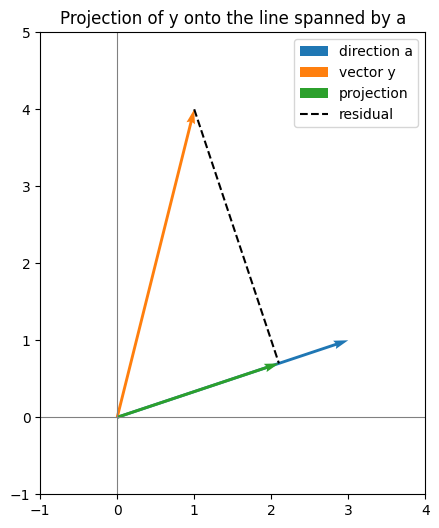

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))

ax.quiver(0, 0, a[0], a[1], angles="xy", scale_units="xy", scale=1,
          color="tab:blue", label="direction a")
ax.quiver(0, 0, y[0], y[1], angles="xy", scale_units="xy", scale=1,
          color="tab:orange", label="vector y")
ax.quiver(0, 0, projection[0], projection[1], angles="xy", scale_units="xy", scale=1,
          color="tab:green", label="projection")
ax.plot([y[0], projection[0]], [y[1], projection[1]], "k--", label="residual")

ax.axhline(0, color="grey", linewidth=0.8)
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_xlim(-1, 4)
ax.set_ylim(-1, 5)
ax.set_aspect("equal")
ax.set_title("Projection of y onto the line spanned by a")
ax.legend()
plt.show()

### Projection onto a column space

For a matrix $A$ with linearly independent columns, the projection of $b$ onto the column space of
$A$ is

$$
\hat{b} = A (A^T A)^{-1} A^T b.
$$

The coefficient vector $(A^T A)^{-1} A^T b$ is the least-squares solution. In code, use
`np.linalg.lstsq` instead of forming the inverse explicitly.

In [6]:
A = np.array(
    [
        [1.0, 0.0],
        [1.0, 1.0],
        [1.0, 2.0],
    ]
)
b = np.array([1.0, 2.0, 2.0])

coefficients, residuals, rank, singular_values = np.linalg.lstsq(A, b, rcond=None)
projection = A @ coefficients
residual = b - projection

print("coefficients:", coefficients)
print("rank:", rank)
print("projection:", projection)
print("residual:", residual)
print("A^T residual is zero:", np.allclose(A.T @ residual, 0.0))

coefficients: [1.167 0.5  ]
rank: 2
projection: [1.167 1.667 2.167]
residual: [-0.167  0.333 -0.167]
A^T residual is zero: True


This is exactly linear regression: the fitted values are the projection of the observed target onto
the space spanned by the features, and the residuals are orthogonal to every feature column.

## 3. Determinant

The determinant is a scalar that describes how a square matrix scales volume. In two dimensions,
$|\det(A)|$ is the area scale factor of the transformation. In three dimensions it is the volume
scale factor.

Key facts:

- $A$ is invertible if and only if $\det(A) \ne 0$;
- $\det(AB) = \det(A)\det(B)$;
- $\det(A^{-1}) = 1 / \det(A)$;
- $\det(A) = \prod_i \lambda_i$, where $\lambda_i$ are the eigenvalues;
- a negative determinant includes a reflection.

The determinant is scale-sensitive, so it is not a good standalone measure of conditioning or
feature importance.

In [7]:
A = np.array([[2.0, 1.0], [1.0, 3.0]])
B = np.array([[1.0, 4.0], [2.0, 0.5]])

det_A = np.linalg.det(A)
det_B = np.linalg.det(B)
eigenvalues_A = np.linalg.eigvalsh(A)

print("det(A):", det_A)
print("det(B):", det_B)
print("det(A) * det(B):", det_A * det_B)
print("det(A @ B):", np.linalg.det(A @ B))
print("product of eigenvalues of A:", np.prod(eigenvalues_A))
print("det(A^-1):", np.linalg.det(np.linalg.inv(A)))
print("1 / det(A):", 1.0 / det_A)

det(A): 5.000000000000001
det(B): -7.499999999999999
det(A) * det(B): -37.5
det(A @ B): -37.5
product of eigenvalues of A: 5.0
det(A^-1): 0.2
1 / det(A): 0.19999999999999996


In [8]:
singular = np.array([[1.0, 2.0], [2.0, 4.0]])
print("singular matrix determinant:", np.linalg.det(singular))
print("rank:", np.linalg.matrix_rank(singular))
print("The second column is a multiple of the first, so the matrix collapses area to zero.")

singular matrix determinant: 0.0
rank: 1
The second column is a multiple of the first, so the matrix collapses area to zero.


## 4. Trace

The trace is the sum of the diagonal entries:

$$
\operatorname{tr}(A) = \sum_i A_{ii}.
$$

It also equals the sum of the eigenvalues. Useful identities:

- $\operatorname{tr}(A + B) = \operatorname{tr}(A) + \operatorname{tr}(B)$;
- $\operatorname{tr}(AB) = \operatorname{tr}(BA)$ when the shapes allow the products;
- $\operatorname{tr}(A) = \sum_i \lambda_i$.

The trace is invariant under cyclic permutations, which is why it appears in matrix derivatives and
in the derivation of PCA.

In [9]:
A = np.array([[2.0, 1.0, 0.0], [1.0, 3.0, 1.0], [0.0, 1.0, 4.0]])
B = np.array([[1.0, 2.0, 0.0], [0.0, 1.0, 1.0], [3.0, 0.0, 2.0]])

print("trace(A):", np.trace(A))
print("sum of eigenvalues of A:", np.sum(np.linalg.eigvalsh(A)))
print("trace(A @ B):", np.trace(A @ B))
print("trace(B @ A):", np.trace(B @ A))
print("cyclic property holds:", np.isclose(np.trace(A @ B), np.trace(B @ A)))

trace(A): 9.0
sum of eigenvalues of A: 9.0
trace(A @ B): 16.0
trace(B @ A): 16.0
cyclic property holds: True


## 5. Symmetric positive definite matrices

A square matrix $A$ is **symmetric** when $A = A^T$. It is **positive definite** when

$$
x^T A x > 0 \quad \text{for every nonzero vector } x.
$$

A symmetric matrix is positive definite if and only if all of its eigenvalues are positive.
Equivalent practical checks include:

- all eigenvalues are positive (`np.linalg.eigvalsh`);
- the Cholesky decomposition exists (`np.linalg.cholesky`);
- all leading principal minors are positive (a pencil-and-paper check).

Covariance matrices are symmetric positive semidefinite: $x^T \Sigma x \ge 0$. They are positive
definite when no feature is an exact linear combination of the others. This is why PCA can use the
eigendecomposition of the covariance matrix.

In [10]:
R = rng.normal(size=(3, 3))
S = R @ R.T + 1e-3 * np.eye(3)

print("S is symmetric:", np.allclose(S, S.T))
print("eigenvalues:", np.linalg.eigvalsh(S))
print("all eigenvalues positive:", np.all(np.linalg.eigvalsh(S) > 0))

L = np.linalg.cholesky(S)
print("Cholesky factor shape:", L.shape)
print("Cholesky reconstructs S:", np.allclose(L @ L.T, S))

S is symmetric: True
eigenvalues: [0.001 1.396 6.847]
all eigenvalues positive: True
Cholesky factor shape: (3, 3)
Cholesky reconstructs S: True


In [11]:
N = np.array([[1.0, 2.0], [2.0, 1.0]])
x = np.array([1.0, -1.0])

print("N is symmetric:", np.allclose(N, N.T))
print("eigenvalues:", np.linalg.eigvalsh(N))
print("quadratic form x^T N x:", x @ N @ x)
print("N is not positive definite because one eigenvalue is negative.")

N is symmetric: True
eigenvalues: [-1.  3.]
quadratic form x^T N x: -2.0
N is not positive definite because one eigenvalue is negative.


### Quadratic forms

The expression $x^T A x$ defines a quadratic form. For a positive definite matrix, its level sets
are ellipses (in 2D) or ellipsoids (in higher dimensions). For an indefinite matrix, the level sets
are hyperbolas: some directions increase the value and others decrease it.

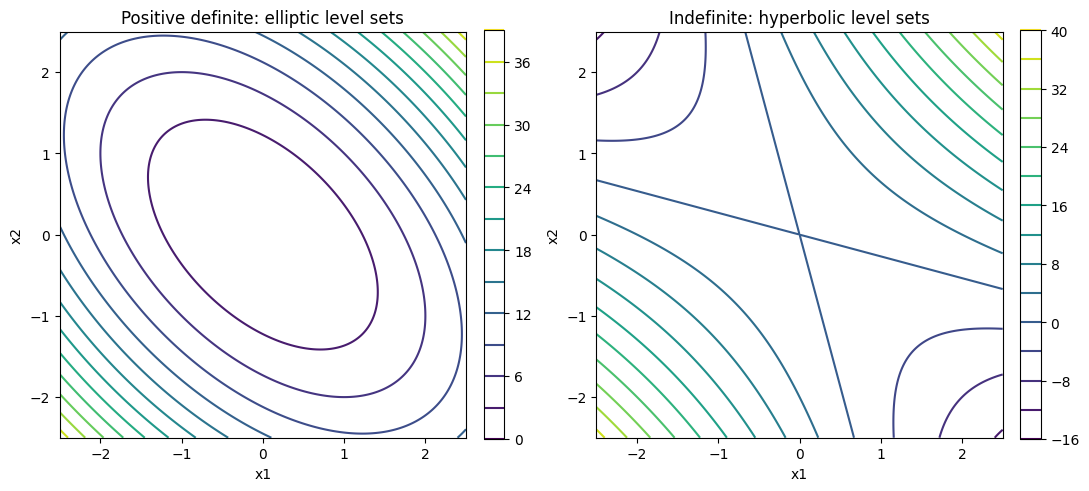

In [12]:
x_grid = np.linspace(-2.5, 2.5, 300)
y_grid = np.linspace(-2.5, 2.5, 300)
X, Y = np.meshgrid(x_grid, y_grid)

A_pd = np.array([[2.0, 1.0], [1.0, 2.0]])
A_indefinite = np.array([[1.0, 2.0], [2.0, 1.0]])

Z_pd = A_pd[0, 0] * X**2 + 2 * A_pd[0, 1] * X * Y + A_pd[1, 1] * Y**2
Z_indefinite = (
    A_indefinite[0, 0] * X**2
    + 2 * A_indefinite[0, 1] * X * Y
    + A_indefinite[1, 1] * Y**2
)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, Z, title in [
    (axes[0], Z_pd, "Positive definite: elliptic level sets"),
    (axes[1], Z_indefinite, "Indefinite: hyperbolic level sets"),
]:
    contour = ax.contour(X, Y, Z, levels=12, cmap="viridis")
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_aspect("equal")
    fig.colorbar(contour, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

## 6. Eigenvalues, eigenvectors, and diagonalization

An eigenvector $v$ of a square matrix $A$ satisfies

$$
A v = \lambda v,
$$

where $\lambda$ is the eigenvalue. If $A$ has a full set of linearly independent eigenvectors, it can
be diagonalized:

$$
A = V \Lambda V^{-1},
$$

where the columns of $V$ are eigenvectors and $\Lambda$ is diagonal. A symmetric matrix is even
better: it can be **orthogonally** diagonalized as

$$
A = Q \Lambda Q^T,
$$

where $Q$ is orthogonal ($Q^T Q = I$). Use `np.linalg.eigh` for symmetric matrices; it is faster and
numerically more stable than `np.linalg.eig`.

Diagonalization makes matrix powers cheap:

$$
A^k = Q \Lambda^k Q^T.
$$

In [13]:
A = np.array([[4.0, 2.0], [2.0, 3.0]])
eigenvalues, Q = np.linalg.eigh(A)
Lambda = np.diag(eigenvalues)

reconstructed = Q @ Lambda @ Q.T
orthogonality_error = np.linalg.norm(Q.T @ Q - np.eye(2))

print("eigenvalues:", eigenvalues)
print("eigenvectors (columns of Q):")
print(Q)
print("Q^T Q:")
print(Q.T @ Q)
print("orthogonality error:", orthogonality_error)
print("reconstruction error:", np.linalg.norm(A - reconstructed))

eigenvalues: [1.438 5.562]
eigenvectors (columns of Q):
[[ 0.615 -0.788]
 [-0.788 -0.615]]
Q^T Q:
[[ 1. -0.]
 [-0.  1.]]
orthogonality error: 3.1541838396005685e-16
reconstruction error: 1.4043333874306805e-15


In [14]:
# A non-symmetric matrix can still be diagonalizable, but the eigenvectors are not orthogonal.
C = np.array([[2.0, 1.0], [0.0, 3.0]])
eigenvalues_C, V = np.linalg.eig(C)
reconstructed_C = V @ np.diag(eigenvalues_C) @ np.linalg.inv(V)

print("eigenvalues:", eigenvalues_C)
print("reconstruction error:", np.linalg.norm(C - reconstructed_C))
print("V^T V is not necessarily the identity:")
print(V.T @ V)

eigenvalues: [2.+0.j 3.+0.j]
reconstruction error: 1.1102230246251565e-16
V^T V is not necessarily the identity:
[[1.   +0.j 0.707+0.j]
 [0.707+0.j 1.   +0.j]]


### Diagonalization in PCA

For a data matrix $X$ with centered columns, the covariance matrix is

$$
\Sigma = \frac{1}{n-1} X^T X.
$$

It is symmetric positive semidefinite. Its eigenvectors are the principal directions and its
eigenvalues are the variance explained along those directions. PCA is therefore an application of
orthogonal diagonalization.

In [15]:
from sklearn.datasets import make_blobs

X, _ = make_blobs(
    n_samples=250,
    centers=1,
    n_features=2,
    cluster_std=1.0,
    random_state=RANDOM_STATE,
)
X = X * np.array([3.0, 0.8])
theta = np.deg2rad(30)
rotation = np.array(
    [
        [np.cos(theta), -np.sin(theta)],
        [np.sin(theta), np.cos(theta)],
    ]
)
X = X @ rotation.T
X = X - X.mean(axis=0)

covariance = np.cov(X, rowvar=False)
eigenvalues, eigenvectors = np.linalg.eigh(covariance)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]
explained_variance_ratio = eigenvalues / eigenvalues.sum()

print("covariance matrix:")
print(covariance)
print("eigenvalues:", eigenvalues)
print("explained variance ratio:", explained_variance_ratio)
print("principal directions (columns):")
print(eigenvectors)

covariance matrix:
[[6.85  3.649]
 [3.649 2.739]]
eigenvalues: [8.982 0.607]
explained variance ratio: [0.937 0.063]
principal directions (columns):
[[-0.863  0.505]
 [-0.505 -0.863]]


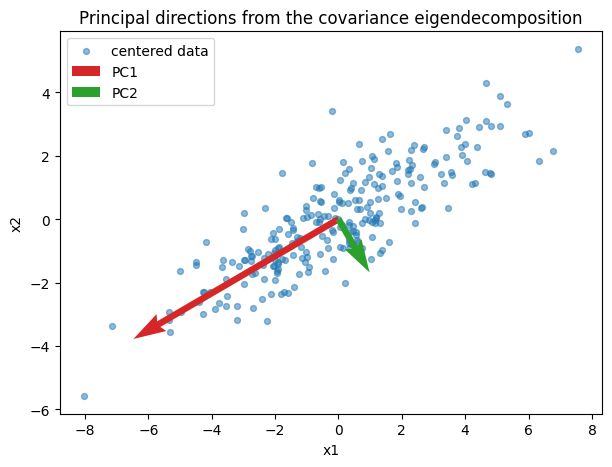

In [16]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(X[:, 0], X[:, 1], s=18, alpha=0.5, label="centered data")

origin = np.zeros(2)
for index, color in enumerate(["tab:red", "tab:green"]):
    direction = eigenvectors[:, index] * np.sqrt(eigenvalues[index]) * 2.5
    ax.quiver(
        origin[0],
        origin[1],
        direction[0],
        direction[1],
        angles="xy",
        scale_units="xy",
        scale=1,
        color=color,
        width=0.012,
        label=f"PC{index + 1}",
    )

ax.set_aspect("equal")
ax.set_title("Principal directions from the covariance eigendecomposition")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.legend()
plt.show()

## 7. Summary

- The inner product gives length, distance, angle, and orthogonality.
- A projection decomposes a vector into a part inside a subspace and a residual orthogonal to it.
- Least squares is a projection onto the column space of the feature matrix.
- The determinant measures volume scaling and detects invertibility; the trace sums eigenvalues.
- Symmetric positive definite matrices have positive eigenvalues, a Cholesky factor, and elliptic
  quadratic forms.
- Symmetric matrices can be orthogonally diagonalized, which is the algebraic basis of PCA.

## Exercises

1. Generate two random 3D vectors and verify Cauchy-Schwarz numerically.
2. Project a 3D vector onto the plane spanned by two independent vectors. Verify that the residual
   is orthogonal to both spanning vectors.
3. Construct a $3 \times 3$ symmetric matrix with one negative eigenvalue and confirm that it is
   not positive definite.
4. Verify that $\operatorname{tr}(AB) = \operatorname{tr}(BA)$ for random rectangular matrices
   where both products are defined.
5. Diagonalize a symmetric $4 \times 4$ matrix with `np.linalg.eigh` and reconstruct it.
6. Compare PCA implemented with the covariance eigendecomposition against scikit-learn's `PCA` on
   the same data.